# EDA: Bank Customer Churn

Análisis exploratorio del dataset público **Bank Customer Churn (Kaggle)**: clientes de un banco europeo (Francia, España y Alemania), ~10 000 registros.

**Objetivo:** identificar qué clientes se fugan (`Exited = 1`) y proponer acciones de retención priorizadas por clientes y saldo en riesgo.

**Reglas de este notebook**
- El dataset **no tiene fechas**: no hay análisis WoW/MoM. La antigüedad (`Tenure`) son años como cliente, no tiempo calendario.
- Se habla de **tasa de fuga por segmento**, no de "probabilidad de fuga" (eso exigiría un modelo).
- Las conclusiones de la sección 5 se escriben **después** de ver tus propios resultados.
- Los segmentos usan **los mismos cortes que el SQL** (script `02_segmentacion.sql`), para poder comparar ambos resultados.

**Contenido:** 1. Carga y revisión · 2. Limpieza · 3. Churn global y por segmento · 4. Gráficos · 5. Hallazgos de negocio · 6. Limitaciones

In [1]:
%pip install pandas numpy matplotlib seaborn

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   --------- ------------------------------ 2.4/9.5 MB 11.8 MB/s eta 0:00:01
   ------------------- -------------------- 4.7/9.5 MB 11.8 MB/s eta 0:00:01
   ----------------------------- ---------- 7.1/9.5 MB 11.6 MB/s eta 0:00:01
   ---------------------------------------  9.4/9.5 MB 11.7 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 10.9 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ------------------------------------- -- 2.4/2.5 MB 11.8 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 10.9 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ------------ --------------------------- 2.4/7.3 MB 11.8 MB/s eta 0:00:01
   --------------------------- ------------ 5.0/7.3 MB 11.8 MB/s eta 0:00:01
   -------------------------------------- - 7.1/7.3 MB 11.8 MB/s eta 0:00:01
   --------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Rutas relativas: el notebook vive en notebooks/, el CSV en data/.
RUTA_CSV = Path("../data/Churn_Modelling.csv")
CARPETA_FIGURAS = Path("../docs")          # aquí se guardan los gráficos como PNG
CARPETA_FIGURAS.mkdir(exist_ok=True)

def guardar(nombre):
    """Guarda la figura actual en docs/ para usarla en el README."""
    plt.savefig(CARPETA_FIGURAS / f"eda_{nombre}.png", dpi=150, bbox_inches="tight")

## 1. Carga y revisión

In [3]:
df_raw = pd.read_csv(RUTA_CSV)
print(f"Filas: {df_raw.shape[0]:,} | Columnas: {df_raw.shape[1]}")
df_raw.head()

Filas: 10,000 | Columnas: 14


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,"101,348.88",1
1,2,15647311,Hill,608,Spain,Female,41,1,"83,807.86",1,0,1,"112,542.58",0
2,3,15619304,Onio,502,France,Female,42,8,"159,660.80",3,1,0,"113,931.57",1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,"93,826.63",0
4,5,15737888,Mitchell,850,Spain,Female,43,2,"125,510.82",1,1,1,"79,084.10",0


In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [5]:
# Resumen estadístico de las variables numéricas
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
RowNumber,"10,000.00","5,000.50","2,886.90",1.00,"2,500.75","5,000.50","7,500.25","10,000.00"
CustomerId,"10,000.00","15,690,940.57","71,936.19","15,565,701.00","15,628,528.25","15,690,738.00","15,753,233.75","15,815,690.00"
CreditScore,"10,000.00",650.53,96.65,350.00,584.00,652.00,718.00,850.00
Age,"10,000.00",38.92,10.49,18.00,32.00,37.00,44.00,92.00
Tenure,"10,000.00",5.01,2.89,0.00,3.00,5.00,7.00,10.00
Balance,"10,000.00","76,485.89","62,397.41",0.00,0.00,"97,198.54","127,644.24","250,898.09"
NumOfProducts,"10,000.00",1.53,0.58,1.00,1.00,1.00,2.00,4.00
HasCrCard,"10,000.00",0.71,0.46,0.00,0.00,1.00,1.00,1.00
IsActiveMember,"10,000.00",0.52,0.50,0.00,0.00,1.00,1.00,1.00
EstimatedSalary,"10,000.00","100,090.24","57,510.49",11.58,"51,002.11","100,193.91","149,388.25","199,992.48"


In [6]:
# Nulos por columna, duplicados y valores únicos
revision = pd.DataFrame({
    "nulos": df_raw.isna().sum(),
    "tipo": df_raw.dtypes.astype(str),
    "valores_unicos": df_raw.nunique(),
})
print(revision)
print()
print("Filas duplicadas completas :", df_raw.duplicated().sum())
print("CustomerId duplicados      :", df_raw["CustomerId"].duplicated().sum())

                 nulos     tipo  valores_unicos
RowNumber            0    int64           10000
CustomerId           0    int64           10000
Surname              0      str            2932
CreditScore          0    int64             460
Geography            0      str               3
Gender               0      str               2
Age                  0    int64              70
Tenure               0    int64              11
Balance              0  float64            6382
NumOfProducts        0    int64               4
HasCrCard            0    int64               2
IsActiveMember       0    int64               2
EstimatedSalary      0  float64            9999
Exited               0    int64               2

Filas duplicadas completas : 0
CustomerId duplicados      : 0


In [7]:
# Categorías y binarias: confirmar que los valores son los esperados
for col in ["Geography", "Gender", "NumOfProducts", "HasCrCard", "IsActiveMember", "Exited"]:
    print(col, "->", df_raw[col].value_counts(dropna=False).sort_index().to_dict())

Geography -> {'France': 5014, 'Germany': 2509, 'Spain': 2477}
Gender -> {'Female': 4543, 'Male': 5457}
NumOfProducts -> {1: 5084, 2: 4590, 3: 266, 4: 60}
HasCrCard -> {0: 2945, 1: 7055}
IsActiveMember -> {0: 4849, 1: 5151}
Exited -> {0: 7963, 1: 2037}


**Notas de la revisión** *(completa con lo que veas)*:
- Filas y columnas: …
- Nulos: …
- Duplicados: …
- Valores raros: …

## 2. Limpieza

Cada decisión se documenta. Se parte de una copia para no tocar `df_raw`.

In [8]:
df = df_raw.copy()

# Decisión 1: RowNumber es solo un índice y Surname no aporta al análisis
# (además es un dato personal innecesario). Se descartan.
df = df.drop(columns=["RowNumber", "Surname"])

# Decisión 2: nombres de columna en snake_case, iguales a los de la tabla SQL churn_clientes.
df = df.rename(columns={
    "CustomerId": "customer_id", "CreditScore": "credit_score", "Geography": "geography",
    "Gender": "gender", "Age": "age", "Tenure": "tenure", "Balance": "balance",
    "NumOfProducts": "num_of_products", "HasCrCard": "has_cr_card",
    "IsActiveMember": "is_active_member", "EstimatedSalary": "estimated_salary",
    "Exited": "exited",
})

# Decisión 3: validaciones de rango (mismas reglas que el script 01 de SQL).
chequeos = {
    "age fuera de 18-100":        (~df["age"].between(18, 100)).sum(),
    "credit_score fuera de 300-850": (~df["credit_score"].between(300, 850)).sum(),
    "tenure fuera de 0-10":       (~df["tenure"].between(0, 10)).sum(),
    "balance negativo":           (df["balance"] < 0).sum(),
    "salario negativo":           (df["estimated_salary"] < 0).sum(),
    "num_of_products fuera de 1-4": (~df["num_of_products"].between(1, 4)).sum(),
    "exited no es 0/1":           (~df["exited"].isin([0, 1])).sum(),
    "has_cr_card no es 0/1":      (~df["has_cr_card"].isin([0, 1])).sum(),
    "is_active_member no es 0/1": (~df["is_active_member"].isin([0, 1])).sum(),
}
pd.Series(chequeos, name="filas_con_problema")

age fuera de 18-100              0
credit_score fuera de 300-850    0
tenure fuera de 0-10             0
balance negativo                 0
salario negativo                 0
num_of_products fuera de 1-4     0
exited no es 0/1                 0
has_cr_card no es 0/1            0
is_active_member no es 0/1       0
Name: filas_con_problema, dtype: int64

**Decisiones de limpieza** *(completa según los resultados anteriores; si algún chequeo no es 0, explica qué hiciste)*:
- Se descartaron `RowNumber` y `Surname`.
- …

In [9]:
# Segmentos: MISMOS cortes que 02_segmentacion.sql.
CORTE_SALDO_BAJO = 100_000     # ajusta si cambiaste los umbrales en el script SQL
CORTE_SALDO_MEDIO = 140_000

df["age_group"] = pd.cut(
    df["age"], bins=[17, 30, 40, 50, 60, 200],
    labels=["18-30", "31-40", "41-50", "51-60", "60+"],
)

df["balance_group"] = np.select(
    [df["balance"] == 0, df["balance"] < CORTE_SALDO_BAJO, df["balance"] < CORTE_SALDO_MEDIO],
    ["1-Sin saldo", "2-Bajo", "3-Medio"],
    default="4-Alto",
)

df["tenure_group"] = pd.cut(
    df["tenure"], bins=[-1, 2, 5, 8, 10],
    labels=["0-2", "3-5", "6-8", "9-10"],
)

df["actividad"] = np.where(df["is_active_member"] == 1, "Activo", "Inactivo")
df["tarjeta"] = np.where(df["has_cr_card"] == 1, "Con tarjeta", "Sin tarjeta")

print("Clientes sin grupo asignado:",
      df[["age_group", "balance_group", "tenure_group"]].isna().sum().sum())
df[["age", "age_group", "balance", "balance_group", "tenure", "tenure_group"]].head()

Clientes sin grupo asignado: 0


,age,age_group,balance,balance_group,tenure,tenure_group
0,42,41-50,0.00,1-Sin saldo,2,0-2
1,41,41-50,"83,807.86",2-Bajo,1,0-2
2,42,41-50,"159,660.80",4-Alto,8,6-8
3,39,31-40,0.00,1-Sin saldo,1,0-2
4,43,41-50,"125,510.82",3-Medio,2,0-2


## 3. Churn global y por segmento

La **tasa de fuga** = fugados / total de clientes del segmento. La **diferencia vs global** se mide en puntos porcentuales (pp).

In [10]:
total = len(df)
fugados = int(df["exited"].sum())
churn_global = fugados / total

saldo_total = df["balance"].sum()
saldo_riesgo = df.loc[df["exited"] == 1, "balance"].sum()

print(f"Total de clientes   : {total:,}")
print(f"Clientes fugados    : {fugados:,}")
print(f"Churn rate global   : {churn_global:.2%}")
print(f"Saldo total         : {saldo_total:,.2f}")
print(f"Saldo en riesgo     : {saldo_riesgo:,.2f} ({saldo_riesgo / saldo_total:.2%} del saldo total)")

Total de clientes   : 10,000
Clientes fugados    : 2,037
Churn rate global   : 20.37%
Saldo total         : 764,858,892.88
Saldo en riesgo     : 185,588,094.63 (24.26% del saldo total)


In [11]:
def churn_por(columna, etiqueta=None):
    """Tabla de churn para una dimensión: clientes, fugados, tasa, diferencia vs global,
    peso en el total de fugas y en el saldo en riesgo."""
    g = df.groupby(columna, observed=True).agg(
        clientes=("exited", "size"),
        fugados=("exited", "sum"),
        saldo_en_riesgo=("balance", lambda s: s[df.loc[s.index, "exited"] == 1].sum()),
    )
    g["churn_rate_pct"] = 100 * g["fugados"] / g["clientes"]
    g["dif_vs_global_pp"] = g["churn_rate_pct"] - 100 * churn_global
    g["pct_del_total_de_fugas"] = 100 * g["fugados"] / fugados
    g["pct_del_saldo_en_riesgo"] = 100 * g["saldo_en_riesgo"] / saldo_riesgo if saldo_riesgo else np.nan
    g.index.name = etiqueta or columna
    return g.reset_index()

dimensiones = {
    "geography": "Pais", "gender": "Genero", "age_group": "Edad", "balance_group": "Saldo",
    "tenure_group": "Antiguedad", "num_of_products": "Productos",
    "actividad": "Actividad", "tarjeta": "Tarjeta",
}

tablas = {nombre: churn_por(col, nombre) for col, nombre in dimensiones.items()}

# Tabla larga con todas las dimensiones (equivalente a la consulta del script 03 de SQL)
largo = pd.concat(
    [t.rename(columns={t.columns[0]: "segmento"}).assign(dimension=nombre) for nombre, t in tablas.items()],
    ignore_index=True,
)
largo["segmento"] = largo["segmento"].astype(str)
largo = largo[["dimension", "segmento", "clientes", "fugados", "churn_rate_pct",
               "dif_vs_global_pp", "pct_del_total_de_fugas", "saldo_en_riesgo", "pct_del_saldo_en_riesgo"]]
largo.sort_values(["dimension", "churn_rate_pct"], ascending=[True, False]).reset_index(drop=True)

,dimension,segmento,clientes,fugados,churn_rate_pct,dif_vs_global_pp,pct_del_total_de_fugas,saldo_en_riesgo,pct_del_saldo_en_riesgo
0,Actividad,Inactivo,4849,1302,26.85,6.48,63.92,"118,467,426.82",63.83
1,Actividad,Activo,5151,735,14.27,-6.10,36.08,"67,120,667.81",36.17
2,Antiguedad,9-10,1474,314,21.30,0.93,15.41,"29,328,966.31",15.80
3,Antiguedad,0-2,2496,528,21.15,0.78,25.92,"46,924,795.42",25.28
4,Antiguedad,3-5,3010,625,20.76,0.39,30.68,"56,383,271.19",30.38
5,Antiguedad,6-8,3020,570,18.87,-1.50,27.98,"52,951,061.71",28.53
6,Edad,51-60,797,448,56.21,35.84,21.99,"40,051,408.90",21.58
7,Edad,41-50,2320,788,33.97,13.60,38.68,"71,203,065.16",38.37
8,Edad,60+,464,115,24.78,4.41,5.65,"10,567,926.89",5.69
9,Edad,31-40,4451,538,12.09,-8.28,26.41,"48,955,897.63",26.38


In [12]:
# Segmentos con mayor tasa de fuga. Se exige un tamaño mínimo (como en el script 04 de SQL)
# para no destacar grupos diminutos.
MIN_CLIENTES = 100
(largo[largo["clientes"] >= MIN_CLIENTES]
     .sort_values("churn_rate_pct", ascending=False)
     .head(10)
     .reset_index(drop=True))

,dimension,segmento,clientes,fugados,churn_rate_pct,dif_vs_global_pp,pct_del_total_de_fugas,saldo_en_riesgo,pct_del_saldo_en_riesgo
0,Productos,3,266,220,82.71,62.34,10.80,"18,887,679.16",10.18
1,Edad,51-60,797,448,56.21,35.84,21.99,"40,051,408.90",21.58
2,Edad,41-50,2320,788,33.97,13.60,38.68,"71,203,065.16",38.37
3,Pais,Germany,2509,814,32.44,12.07,39.96,"97,973,915.53",52.79
4,Productos,1,5084,1409,27.71,7.34,69.17,"129,668,607.08",69.87
5,Actividad,Inactivo,4849,1302,26.85,6.48,63.92,"118,467,426.82",63.83
6,Saldo,3-Medio,3250,854,26.28,5.91,41.92,"102,172,509.62",55.05
7,Genero,Female,4543,1139,25.07,4.70,55.92,"101,412,732.23",54.64
8,Edad,60+,464,115,24.78,4.41,5.65,"10,567,926.89",5.69
9,Saldo,4-Alto,1549,357,23.05,2.68,17.53,"57,317,181.38",30.88


In [13]:
# Perfil: fugados vs retenidos (promedios). El saldo tiene muchos ceros, así que se
# muestra también el % de clientes sin saldo.
perfil = df.groupby("exited").agg(
    clientes=("exited", "size"),
    edad_prom=("age", "mean"),
    score_prom=("credit_score", "mean"),
    antiguedad_prom=("tenure", "mean"),
    saldo_prom=("balance", "mean"),
    salario_est_prom=("estimated_salary", "mean"),
    productos_prom=("num_of_products", "mean"),
    pct_activos=("is_active_member", lambda s: 100 * s.mean()),
    pct_sin_saldo=("balance", lambda s: 100 * (s == 0).mean()),
)
perfil.index = perfil.index.map({0: "Retenido", 1: "Fugado"})
perfil

,clientes,edad_prom,score_prom,antiguedad_prom,saldo_prom,salario_est_prom,productos_prom,pct_activos,pct_sin_saldo
exited,,,,,,,,,
Retenido,7963,37.41,651.85,5.03,"72,745.30","99,738.39",1.54,55.46,39.14
Fugado,2037,44.84,645.35,4.93,"91,108.54","101,465.68",1.48,36.08,24.55


> **Validación cruzada con SQL:** el churn global y la tabla por segmento deben coincidir con los de
> `03_kpis_cte.sql`. Si no coinciden, revisa los cortes de los grupos (saldo, edad, antigüedad) o los filtros.

## 4. Gráficos

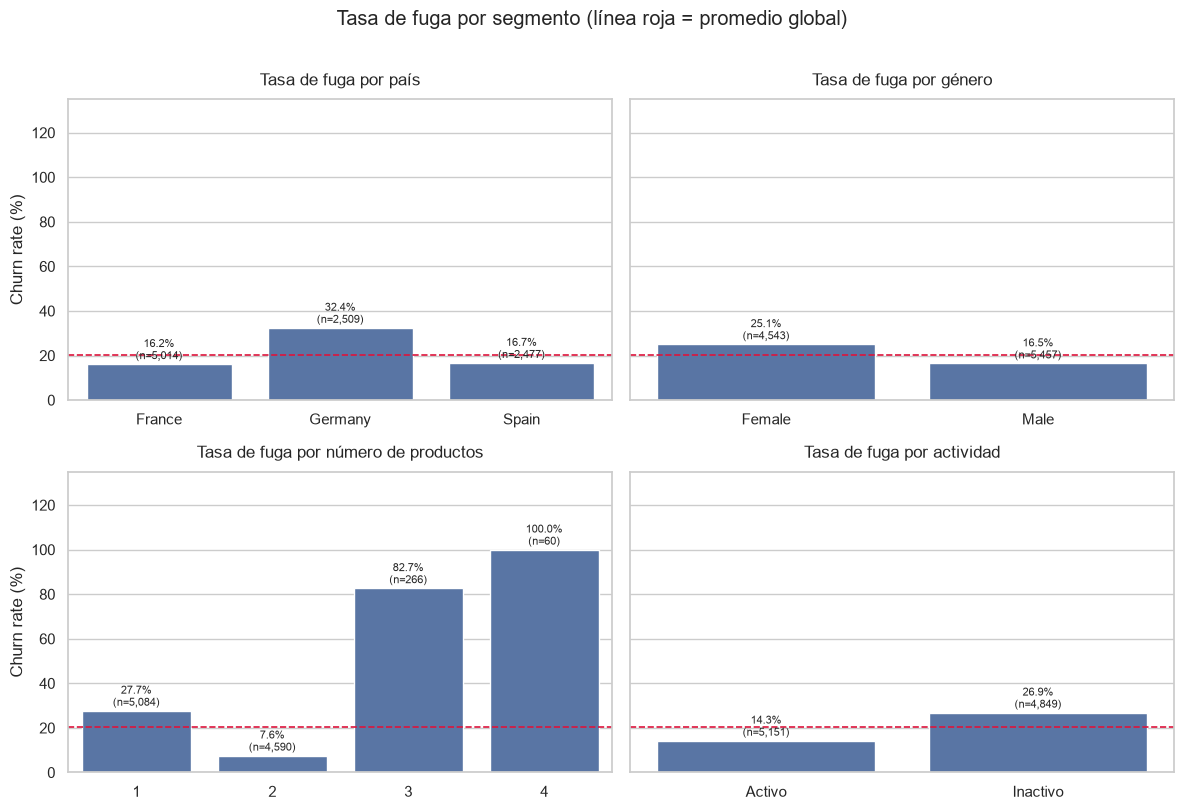

In [14]:
# 4.1 Churn por país, género, número de productos y actividad
specs = [("geography", "País"), ("gender", "Género"),
         ("num_of_products", "Número de productos"), ("actividad", "Actividad")]
ymax = max(churn_por(c)["churn_rate_pct"].max() for c, _ in specs) * 1.35   # espacio para las etiquetas

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for ax, (columna, titulo) in zip(axes.ravel(), specs):
    t = churn_por(columna)
    sns.barplot(data=t, x=columna, y="churn_rate_pct", ax=ax, color="#4C72B0")
    ax.axhline(100 * churn_global, color="crimson", ls="--", lw=1.2)
    for i, fila in t.iterrows():
        ax.text(i, fila["churn_rate_pct"] + 0.8, f"{fila['churn_rate_pct']:.1f}%\n(n={int(fila['clientes']):,})",
                ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0, ymax)
    ax.set_title(f"Tasa de fuga por {titulo.lower()}", pad=10)
    ax.set_xlabel("")
    ax.set_ylabel("Churn rate (%)")
fig.suptitle("Tasa de fuga por segmento (línea roja = promedio global)", y=1.01)
plt.tight_layout()
guardar("churn_por_segmento")
plt.show()

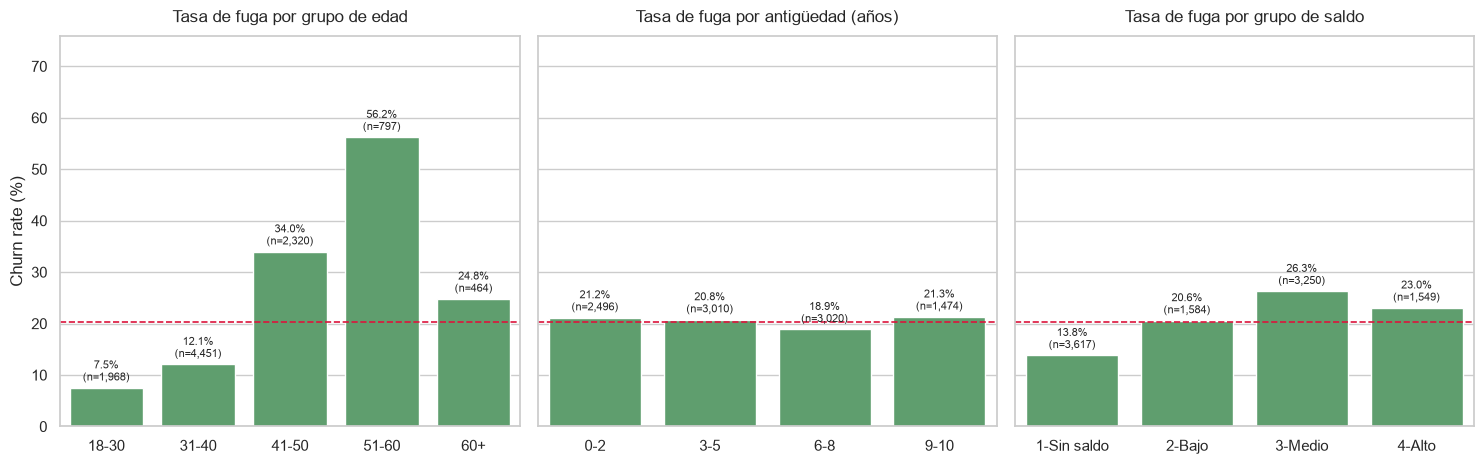

In [15]:
# 4.2 Churn por grupo de edad, antigüedad y saldo
specs = [("age_group", "grupo de edad"), ("tenure_group", "antigüedad (años)"), ("balance_group", "grupo de saldo")]
ymax = max(churn_por(c)["churn_rate_pct"].max() for c, _ in specs) * 1.35

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
for ax, (columna, titulo) in zip(axes, specs):
    t = churn_por(columna)
    t[columna] = t[columna].astype(str)
    sns.barplot(data=t, x=columna, y="churn_rate_pct", ax=ax, color="#55A868")
    ax.axhline(100 * churn_global, color="crimson", ls="--", lw=1.2)
    for i, fila in t.iterrows():
        ax.text(i, fila["churn_rate_pct"] + 0.8, f"{fila['churn_rate_pct']:.1f}%\n(n={int(fila['clientes']):,})",
                ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0, ymax)
    ax.set_title(f"Tasa de fuga por {titulo}", pad=10)
    ax.set_xlabel("")
    ax.set_ylabel("Churn rate (%)")
plt.tight_layout()
guardar("churn_edad_antiguedad_saldo")
plt.show()

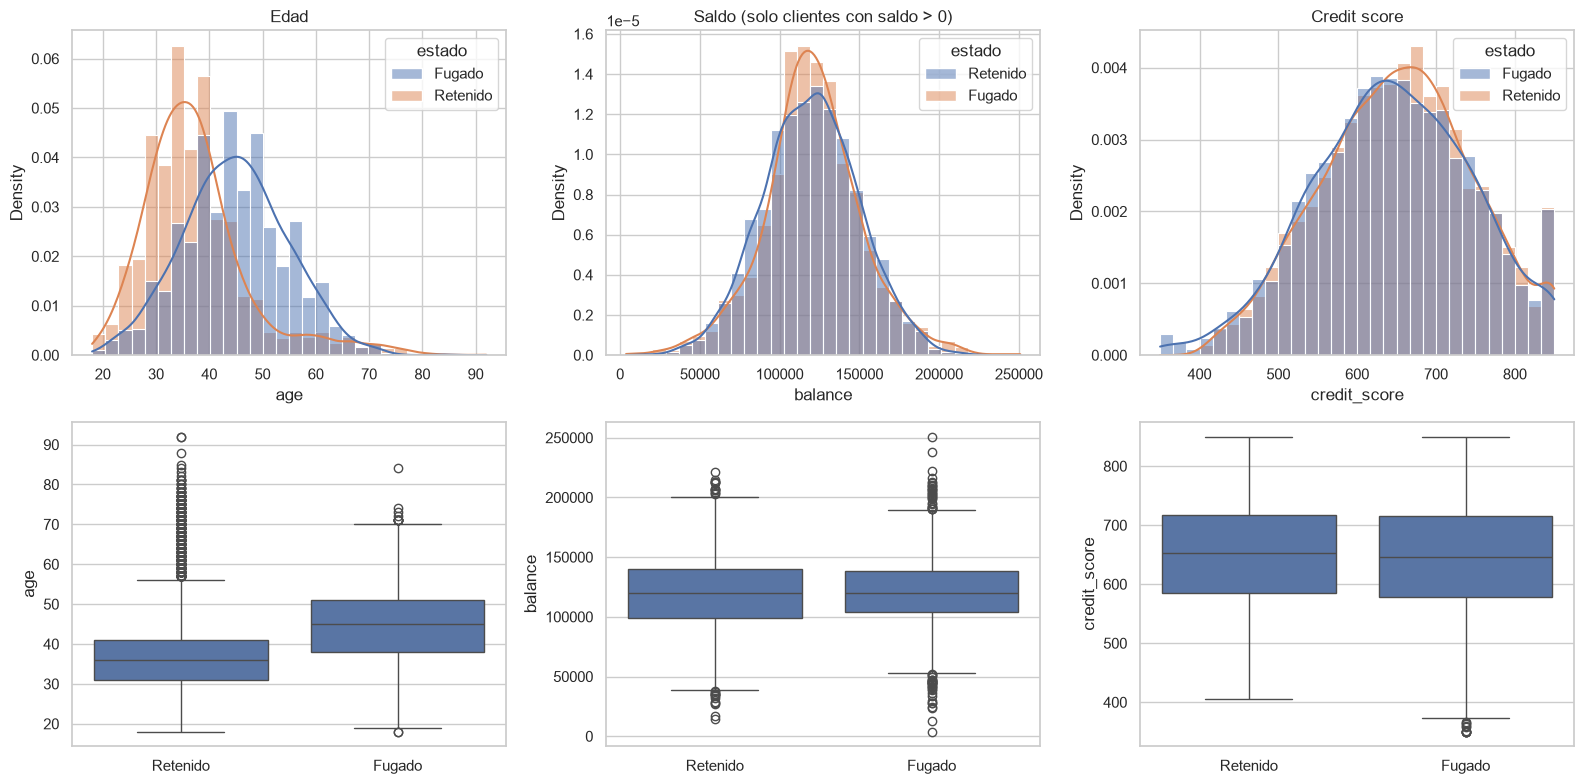

In [16]:
# 4.3 Distribución de edad, saldo y credit score, separadas por Exited
etiquetas = df.assign(estado=df["exited"].map({0: "Retenido", 1: "Fugado"}))

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

# Histogramas (saldo: solo clientes con saldo > 0, porque los ceros dominan la escala)
sns.histplot(data=etiquetas, x="age", hue="estado", bins=30, kde=True, stat="density",
             common_norm=False, ax=axes[0, 0])
axes[0, 0].set_title("Edad")
sns.histplot(data=etiquetas[etiquetas["balance"] > 0], x="balance", hue="estado", bins=30, kde=True,
             stat="density", common_norm=False, ax=axes[0, 1])
axes[0, 1].set_title("Saldo (solo clientes con saldo > 0)")
sns.histplot(data=etiquetas, x="credit_score", hue="estado", bins=30, kde=True, stat="density",
             common_norm=False, ax=axes[0, 2])
axes[0, 2].set_title("Credit score")

# Boxplots
sns.boxplot(data=etiquetas, x="estado", y="age", ax=axes[1, 0], order=["Retenido", "Fugado"])
sns.boxplot(data=etiquetas[etiquetas["balance"] > 0], x="estado", y="balance", ax=axes[1, 1],
            order=["Retenido", "Fugado"])
sns.boxplot(data=etiquetas, x="estado", y="credit_score", ax=axes[1, 2], order=["Retenido", "Fugado"])
for ax in axes[1]:
    ax.set_xlabel("")
plt.tight_layout()
guardar("distribuciones")
plt.show()

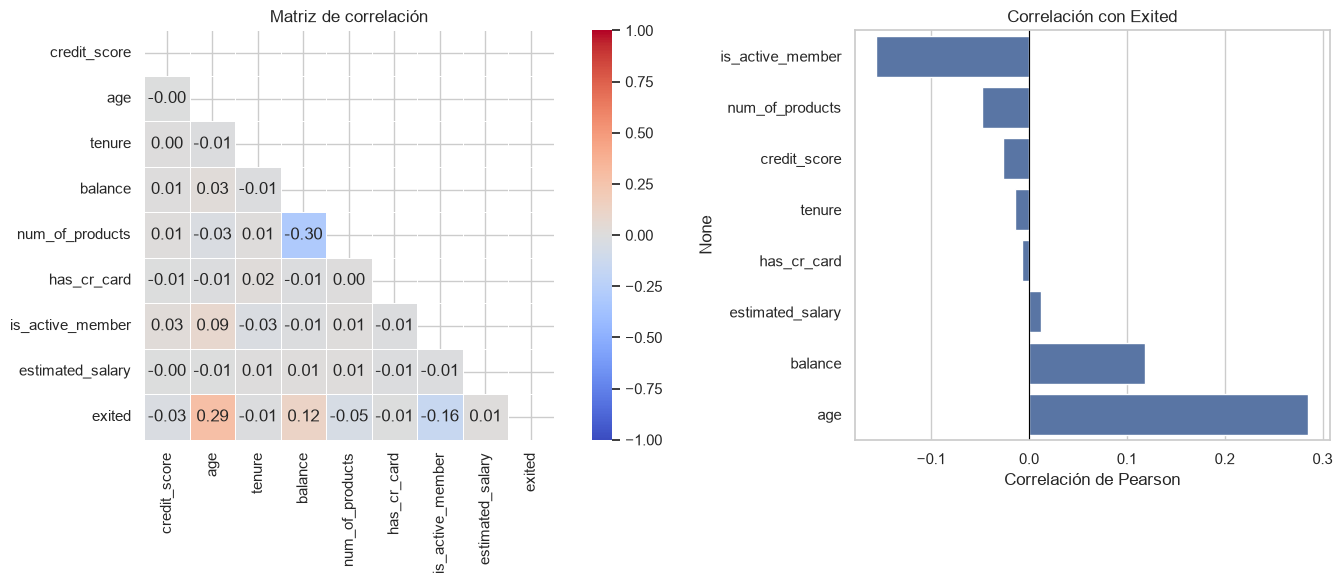

,correlacion_con_exited
is_active_member,-0.16
num_of_products,-0.05
credit_score,-0.03
tenure,-0.01
has_cr_card,-0.01
estimated_salary,0.01
balance,0.12
age,0.29


In [17]:
# 4.4 Heatmap de correlación (variables numéricas vs Exited)
# Correlación de Pearson. Para variables binarias (0/1) es la correlación punto-biserial:
# sirve como orientación, no como medida causal.
numericas = ["credit_score", "age", "tenure", "balance", "num_of_products",
             "has_cr_card", "is_active_member", "estimated_salary", "exited"]
corr = df[numericas].corr()

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.6, 1]})
mascara = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, ax=axes[0])
axes[0].set_title("Matriz de correlación")

corr_exited = corr["exited"].drop("exited").sort_values()
sns.barplot(x=corr_exited.values, y=corr_exited.index, ax=axes[1], color="#4C72B0")
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_title("Correlación con Exited")
axes[1].set_xlabel("Correlación de Pearson")
plt.tight_layout()
guardar("correlacion")
plt.show()

corr_exited.to_frame("correlacion_con_exited")

In [18]:
# 4.5 Cruce país x actividad: ¿el efecto de una variable se mantiene al separar por otra?
cruce = (df.groupby(["geography", "actividad"])
           .agg(clientes=("exited", "size"), churn_rate_pct=("exited", lambda s: 100 * s.mean()))
           .reset_index())
cruce

,geography,actividad,clientes,churn_rate_pct
0,France,Activo,2591,11.50
1,France,Inactivo,2423,21.13
2,Germany,Activo,1248,23.72
3,Germany,Inactivo,1261,41.08
4,Spain,Activo,1312,10.75
5,Spain,Inactivo,1165,23.35


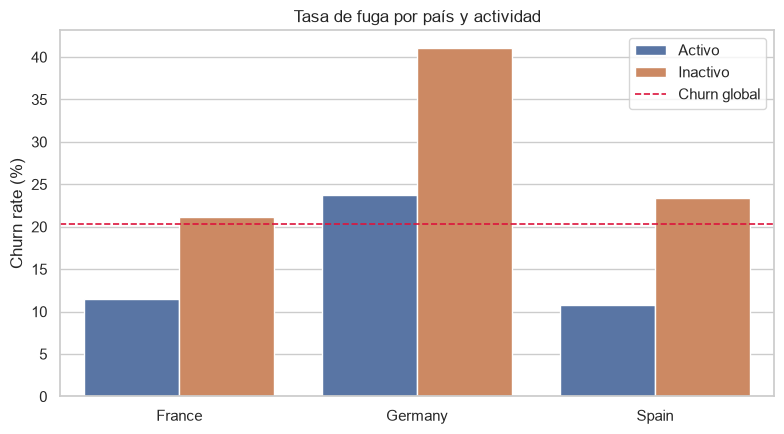

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=cruce, x="geography", y="churn_rate_pct", hue="actividad", ax=ax)
ax.axhline(100 * churn_global, color="crimson", ls="--", lw=1.2, label="Churn global")
ax.set_title("Tasa de fuga por país y actividad")
ax.set_xlabel("")
ax.set_ylabel("Churn rate (%)")
ax.legend()
plt.tight_layout()
guardar("pais_x_actividad")
plt.show()

## 5. Hallazgos de negocio

### Hallazgo 1: la fuga se concentra en clientes de 41 a 60 años
- **Cifra:** los clientes de 51-60 años tienen una tasa de fuga de 56.2 % (n=797) y los de 41-50, de 34.0 % (n=2,320), frente a ~20.4 % global. Los menores de 40 están en 7.5 % (18-30) y 12.1 % (31-40).
- **Evidencia:** gráfico 4.2 (por grupo de edad), boxplot de edad (los fugados tienen una mediana de ~45 años frente a ~36 de los retenidos) y correlación edad-Exited de 0.29, la más alta de todas las variables.
- **Acción sugerida:** programa de retención dirigido a los ~3,100 clientes de 41-60 años (ofertas de fidelización, contacto proactivo de un asesor). Medirlo con la tasa de fuga de ese grupo contra un grupo de control.
- **Salvedad:** en 60+ la tasa baja a 24.8 % (n=464); el patrón no es "a más edad, más fuga". Es una asociación, no una causa.

### Hallazgo 2: los clientes inactivos se fugan casi el doble
- **Cifra:** inactivos 26.9 % (n=4,849) frente a activos 14.3 % (n=5,151).
- **Evidencia:** gráfico 4.1 (actividad) y cruce país × actividad: en los tres países los inactivos se fugan más.
- **Acción sugerida:** campaña de reactivación (uso de app o tarjeta, beneficios por actividad) sobre el segmento inactivo.
- **Salvedad:** la inactividad puede ser un síntoma previo a la fuga y no su causa.

### Hallazgo 3: Alemania tiene el doble de fuga que Francia y España
- **Cifra:** Alemania 32.4 % (n=2,509), Francia 16.2 % (n=5,014), España 16.7 % (n=2,477).
- **Evidencia:** gráfico 4.1 (país) y cruce país × actividad: los alemanes inactivos llegan a ~41 % y los activos a ~23 %, por encima de los activos de Francia y España (~11 %). El efecto del país no se explica solo por la actividad.
- **Acción sugerida:** investigar la causa en Alemania (producto, precio, competencia, atención) antes de diseñar la acción, y priorizar ahí los esfuerzos de retención.
- **Salvedad:** con estos datos no se puede saber por qué; solo que es un segmento de riesgo.

### Hallazgo 4: el número de productos muestra un patrón inesperado
- **Cifra:** 2 productos tienen solo 7.6 % de fuga (n=4,590), 1 producto 27.7 % (n=5,084), 3 productos 82.7 % (n=266) y 4 productos 100 % (n=60).
- **Evidencia:** gráfico 4.1 (productos). La correlación lineal es baja (-0.05) porque la relación no es lineal; por eso no basta mirar el heatmap.
- **Acción sugerida:** revisar con el área de negocio por qué los clientes con 3 o más productos casi siempre se van (~326 clientes). Como hipótesis a validar: llevar a los clientes de 1 producto a 2.
- **Salvedad:** los grupos de 3 y 4 productos son pequeños y una tasa de 100 % es sospechosa. Podría reflejar un efecto de cómo se generó el dataset. No afirmar causalidad.

### Hallazgo 5: variables que no distinguen a los fugados
- La antigüedad es casi plana (18.9 % a 21.3 % entre grupos), y el credit score y el salario estimado casi no se diferencian entre fugados y retenidos (correlaciones ≈ 0). No sirven para priorizar clientes.

### Recomendación priorizada
Concentrar la retención en clientes de 41-60 años, en especial inactivos y de Alemania. Cuantificar con tus cifras reales: **[N] clientes, [X] % de las fugas y [Y] de saldo en riesgo** (sale de tu tabla `largo` y del Pareto del script 05).

## 6. Limitaciones

- **Sin fechas:** no se puede medir evolución en el tiempo ni estacionalidad (por eso no hay churn WoW/MoM). `Tenure` es antigüedad, no una fecha.
- **Dataset público de Kaggle** de un banco europeo (Francia, España, Alemania): no representa a la banca peruana ni se sabe cómo se generó o muestreó.
- **Correlación no implica causalidad:** los patrones describen asociaciones, no causas.
- **Tasa de fuga ≠ probabilidad individual:** no hay modelo predictivo en este análisis (la regresión logística es una fase opcional).
- **Saldo en riesgo** es el saldo registrado de los clientes fugados; no es una pérdida económica real ni un ingreso perdido.
- **Cortes de los grupos** (edad, saldo, antigüedad) son decisiones del análisis; otros cortes podrían cambiar la lectura.
- **Grupos pequeños con tasas extremas:** los clientes con 3 y 4 productos tienen tasas de 82.7 % (n=266) y 100 % (n=60). Con tan pocos clientes y valores tan extremos, esos resultados son poco estables y podrían reflejar cómo se generó el dataset, no un comportamiento real del banco.
- **Variables analizadas una por una:** los gráficos por segmento miran cada variable por separado. Edad, país y actividad pueden estar relacionadas entre sí, y no se controló el efecto de unas sobre otras (solo se hizo un cruce país × actividad). Un modelo multivariable podría matizar los resultados.
- **Sin pruebas estadísticas:** las diferencias entre segmentos se describen con tasas, pero no se contrastaron con pruebas de significancia ni intervalos de confianza.
- **Correlación lineal limitada:** el heatmap usa correlación de Pearson, que no captura relaciones no lineales (por ejemplo, la de número de productos, donde 2 productos tiene la menor fuga y 3 o 4 la mayor).
- **Clases desbalanceadas:** solo ~20 % de los clientes se fugó, lo que importa si más adelante se construye un modelo predictivo.
- **Muchos clientes sin saldo:** el 36 % (3,617 de 10,000) tiene balance = 0. Por eso el saldo se analiza con un grupo propio ("Sin saldo") y el histograma y el boxplot del saldo se hicieron solo con clientes con saldo > 0.
- **Falta contexto de negocio:** el dataset no incluye motivos de salida, reclamos, canales de atención, precios ni productos específicos, así que no se puede explicar *por qué* se van los clientes, solo *quiénes* se van.